In [2]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score

In [3]:
data = pd.read_csv('Depression Student Dataset.csv')
data.head()

,Gender,Age,Academic Pressure,Study Satisfaction,Sleep Duration,Dietary Habits,Have you ever had suicidal thoughts ?,Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,Male,28,2.0,4.0,7-8 hours,Moderate,Yes,9,2,Yes,No
1,Male,28,4.0,5.0,5-6 hours,Healthy,Yes,7,1,Yes,No
2,Male,25,1.0,3.0,5-6 hours,Unhealthy,Yes,10,4,No,Yes
3,Male,23,1.0,4.0,More than 8 hours,Unhealthy,Yes,7,2,Yes,No
4,Female,31,1.0,5.0,More than 8 hours,Healthy,Yes,4,2,Yes,No


In [4]:
data.describe()

,Age,Academic Pressure,Study Satisfaction,Study Hours,Financial Stress
count,502.000000,502.000000,502.000000,502.000000,502.000000
mean,26.241036,3.003984,3.075697,6.404382,2.928287
std,4.896501,1.390007,1.373490,3.742434,1.425053
min,18.000000,1.000000,1.000000,0.000000,1.000000
25%,22.000000,2.000000,2.000000,3.000000,2.000000
50%,26.500000,3.000000,3.000000,7.000000,3.000000
75%,30.000000,4.000000,4.000000,10.000000,4.000000
max,34.000000,5.000000,5.000000,12.000000,5.000000


In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 502 entries, 0 to 501
Data columns (total 11 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Gender                                 502 non-null    str    
 1   Age                                    502 non-null    int64  
 2   Academic Pressure                      502 non-null    float64
 3   Study Satisfaction                     502 non-null    float64
 4   Sleep Duration                         502 non-null    str    
 5   Dietary Habits                         502 non-null    str    
 6   Have you ever had suicidal thoughts ?  502 non-null    str    
 7   Study Hours                            502 non-null    int64  
 8   Financial Stress                       502 non-null    int64  
 9   Family History of Mental Illness       502 non-null    str    
 10  Depression                             502 non-null    str    
dtypes: float64(2), in

In [6]:
data_map = {
    "Yes": 1, "No": 0,

    "Male": 0, "Female": 1,

    "Less than 5 hours": 0,
    "5-6 hours": 1,
    "7-8 hours": 2,
    "More than 8 hours": 3,

    "Unhealthy": 0,
    "Moderate": 1,
    "Healthy": 2
}

data = data.replace(data_map).astype(int)

In [7]:
data.head()

,Gender,Age,Academic Pressure,Study Satisfaction,Sleep Duration,Dietary Habits,Have you ever had suicidal thoughts ?,Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,0,28,2,4,2,1,1,9,2,1,0
1,0,28,4,5,1,2,1,7,1,1,0
2,0,25,1,3,1,0,1,10,4,0,1
3,0,23,1,4,3,0,1,7,2,1,0
4,1,31,1,5,3,2,1,4,2,1,0


In [8]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 502 entries, 0 to 501
Data columns (total 11 columns):
 #   Column                                 Non-Null Count  Dtype
---  ------                                 --------------  -----
 0   Gender                                 502 non-null    int64
 1   Age                                    502 non-null    int64
 2   Academic Pressure                      502 non-null    int64
 3   Study Satisfaction                     502 non-null    int64
 4   Sleep Duration                         502 non-null    int64
 5   Dietary Habits                         502 non-null    int64
 6   Have you ever had suicidal thoughts ?  502 non-null    int64
 7   Study Hours                            502 non-null    int64
 8   Financial Stress                       502 non-null    int64
 9   Family History of Mental Illness       502 non-null    int64
 10  Depression                             502 non-null    int64
dtypes: int64(11)
memory usage: 43.3 KB


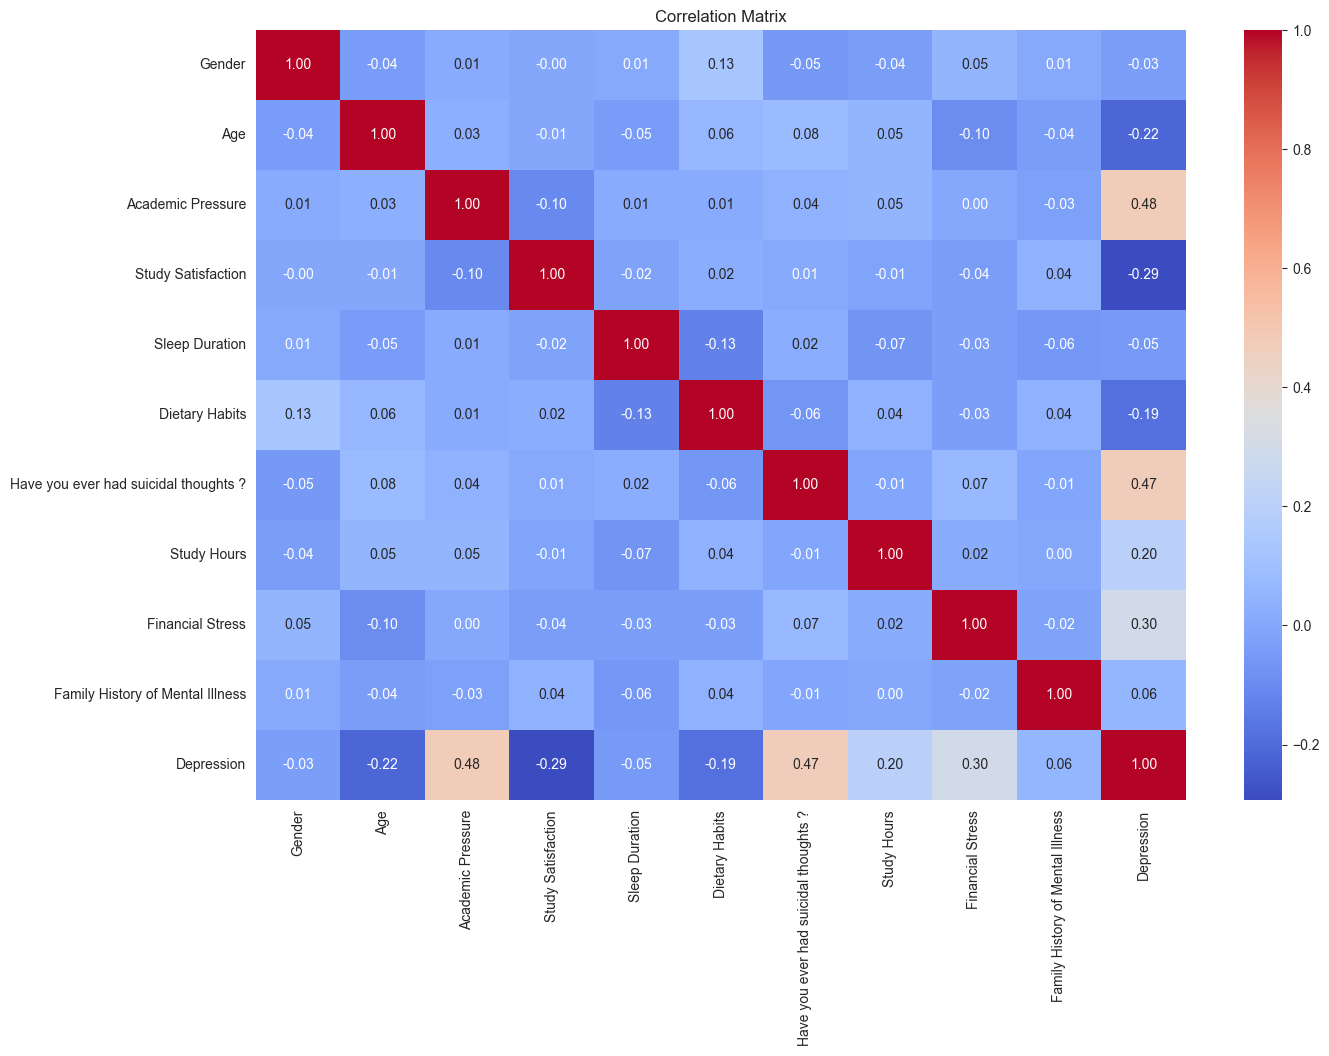

In [59]:
plt.figure(figsize=(15, 10))
correlation_matrix = data.corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

In [60]:
X = data.drop(columns=['Depression'])
y = data['Depression']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y)

In [61]:
X_train.shape, X_test.shape

((401, 10), (101, 10))

In [62]:
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [1, 3, 5],
    'min_samples_leaf': [10, 20, 30],
    'min_samples_split' : [10, 20, 30],
    'criterion': ['gini', 'entropy']
}

rf = RandomForestClassifier(n_jobs=-1)

grid_search = GridSearchCV(estimator=rf,
                           param_grid=param_grid,
                           cv=5,
                           scoring='recall')

grid_search.fit(X_train, y_train)

print("Лучшие параметры:", grid_search.best_params_)
print("Лучший recall:", grid_search.best_score_)

Лучшие параметры: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 10, 'min_samples_split': 30, 'n_estimators': 200}
Лучший recall: 0.9152439024390244


In [63]:
best_rf = grid_search.best_estimator_
y_pred = best_rf.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.98      0.80      0.88        50
           1       0.83      0.98      0.90        51

    accuracy                           0.89       101
   macro avg       0.90      0.89      0.89       101
weighted avg       0.90      0.89      0.89       101



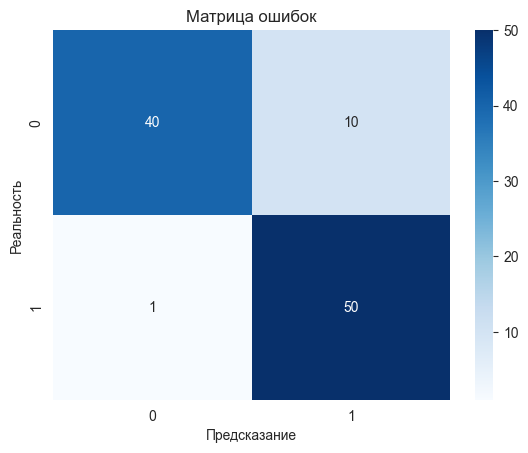

In [64]:
conf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Предсказание')
plt.ylabel('Реальность')
plt.title('Матрица ошибок')
plt.show()

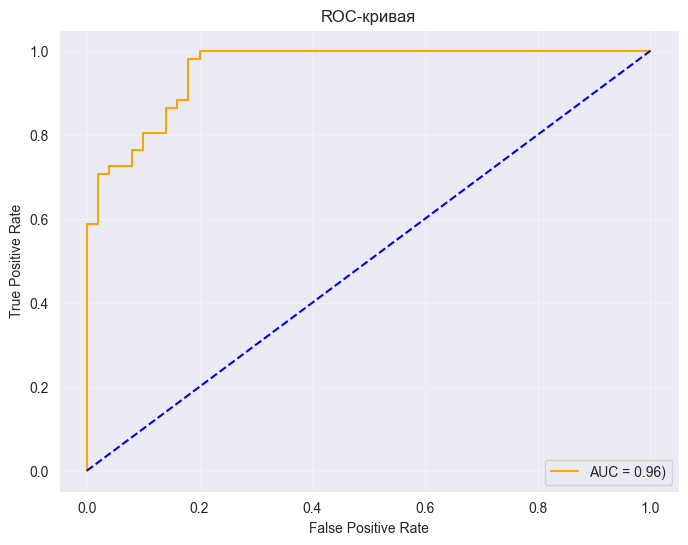

In [65]:
y_probs = best_rf.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_probs)
roc_auc = roc_auc_score(y_test, y_probs)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='orange', label=f'AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='blue', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривая')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

In [66]:
joblib.dump(best_rf, 'rf_model.pkl')

['rf_model.pkl']